In [61]:
import glob
import pandas as pd

files = glob.glob("../data/raw/**/*-street.csv", recursive=True)

crimes = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
crimes.shape

(3440762, 12)

In [62]:
crimes.head()

,Crime ID,Month,Reported by,Falls within,Longitude,Latitude,Location,LSOA code,LSOA name,Crime type,Last outcome category,Context
0,85e05b94ecc10d99ee19e03c0560b7c1a4fe6659e467d0...,2023-09,City of London Police,City of London Police,-0.105965,51.518514,On or near Further/Higher Educational Building,E01000916,Camden 027B,Theft from the person,Investigation complete; no suspect identified,NaN
1,40af5b360da01ba9fcf3882dfa6cb95042faf3934eb55c...,2023-09,City of London Police,City of London Police,-0.106220,51.518275,On or near B500,E01000916,Camden 027B,Theft from the person,Investigation complete; no suspect identified,NaN
2,44a51a04eca615ec9169edf95e9356dba4e839a64390ae...,2023-09,City of London Police,City of London Police,-0.107682,51.517786,On or near B521,E01000917,Camden 027C,Violence and sexual offences,Unable to prosecute suspect,NaN
3,5df2310497d43aacd38c196b116fe570dd7e7d35a8601e...,2023-09,City of London Police,City of London Police,-0.110350,51.518090,On or near Holborn,E01000917,Camden 027C,Shoplifting,Investigation complete; no suspect identified,NaN
4,7924710672a4388d469d1ad08a785fe40b34cbeb54e41a...,2023-09,City of London Police,City of London Police,-0.107682,51.517786,On or near B521,E01000917,Camden 027C,Violence and sexual offences,Status update unavailable,NaN


In [63]:
crimes["Month"] = pd.to_datetime(crimes["Month"])


In [64]:
before = len(crimes)
crimes = crimes.dropna(subset=["Latitude", "Longitude", "LSOA name"]).copy()
print(f"Dropped {before - len(crimes):,} rows with no location ({(before - len(crimes)) / before:.1%})")

Dropped 12,550 rows with no location (0.4%)


In [65]:
crimes["Borough"] = crimes["LSOA name"].str.rsplit(" ", n=1).str[0]

In [66]:
crimes["Borough"].nunique()

330

In [67]:
crimes["Borough"].value_counts().tail(15)  # the smallest ones, so outsiders show up here

Borough
Chorley              3
Torridge             3
Vale of Glamorgan    3
Fylde                3
Adur                 3
South Ribble         3
Mid Devon            3
Wyre Forest          3
West Devon           2
Barrow-in-Furness    2
Copeland             2
Richmondshire        2
Hambleton            2
Ribble Valley        2
Craven               1
Name: count, dtype: int64

In [68]:
crimes = crimes.drop(columns=["Reported by", "LSOA code", "Last outcome category", "Context", "Crime ID"])
crimes.shape

(3428212, 8)

In [69]:
LONDON = [
    "Barking and Dagenham", "Barnet", "Bexley", "Brent", "Bromley", "Camden",
    "City of London", "Croydon", "Ealing", "Enfield", "Greenwich", "Hackney",
    "Hammersmith and Fulham", "Haringey", "Harrow", "Havering", "Hillingdon",
    "Hounslow", "Islington", "Kensington and Chelsea", "Kingston upon Thames",
    "Lambeth", "Lewisham", "Merton", "Newham", "Redbridge",
    "Richmond upon Thames", "Southwark", "Sutton", "Tower Hamlets",
    "Waltham Forest", "Wandsworth", "Westminster",
]   #I personally don't like this method but it's the most appropriate for London filtering :(

before = len(crimes)
crimes = crimes[crimes["Borough"].isin(LONDON)].copy()
before - len(crimes)
dropped = before - len(crimes)
print(f"Dropped {dropped:,} rows outside London ({dropped / before:.1%})")

Dropped 13,030 rows outside London (0.4%)


In [70]:
crimes["Borough"].value_counts().tail(15)

Borough
Hounslow                  99846
Waltham Forest            92170
Redbridge                 89320
Bromley                   87701
Hammersmith and Fulham    80156
Kensington and Chelsea    79627
Havering                  74319
Barking and Dagenham      72622
Harrow                    64251
Bexley                    60222
Merton                    51161
Sutton                    48438
Richmond upon Thames      44276
Kingston upon Thames      44267
City of London            29749
Name: count, dtype: int64

In [71]:
crimes["Borough"].nunique()

33

In [81]:
latest = crimes["Month"].max()

Timestamp('2026-08-01 00:00:00')

In [82]:
crimes["YearGroup"] = "Year1"
crimes.loc[crimes["Month"] >= "2024-09-01", "YearGroup"] = "Year2"
crimes.loc[crimes["Month"] >= "2025-09-01", "YearGroup"] = "Year3"

In [86]:
crimes[crimes["YearGroup"] == "Year1"]

,Month,Falls within,Longitude,Latitude,Location,LSOA name,Crime type,Borough,YearGroup
0,2023-09-01,City of London Police,-0.105965,51.518514,On or near Further/Higher Educational Building,Camden 027B,Theft from the person,Camden,Year1
1,2023-09-01,City of London Police,-0.106220,51.518275,On or near B500,Camden 027B,Theft from the person,Camden,Year1
2,2023-09-01,City of London Police,-0.107682,51.517786,On or near B521,Camden 027C,Violence and sexual offences,Camden,Year1
3,2023-09-01,City of London Police,-0.110350,51.518090,On or near Holborn,Camden 027C,Shoplifting,Camden,Year1
4,2023-09-01,City of London Police,-0.107682,51.517786,On or near B521,Camden 027C,Violence and sexual offences,Camden,Year1
...,...,...,...,...,...,...,...,...,...
1154145,2024-08-01,Metropolitan Police Service,-0.133538,51.487500,On or near Aylesford Street,Westminster 024G,Vehicle crime,Westminster,Year1
1154146,2024-08-01,Metropolitan Police Service,-0.133480,51.486807,On or near St George'S Square Mews,Westminster 024G,Violence and sexual offences,Westminster,Year1
1154147,2024-08-01,Metropolitan Police Service,-0.137230,51.486309,On or near Parking Area,Westminster 024G,Violence and sexual offences,Westminster,Year1
1154148,2024-08-01,Metropolitan Police Service,-0.136234,51.487435,On or near Chichester Street,Westminster 024G,Violence and sexual offences,Westminster,Year1


In [87]:
crimes.shape

(3415182, 9)

In [88]:
crimes["YearGroup"].value_counts().sort_index()

YearGroup
Year1    1139469
Year2    1150468
Year3    1125245
Name: count, dtype: int64

In [93]:
sample = crimes[(crimes["Borough"] == "Lambeth") & (crimes["YearGroup"] == "Year1")]
points = sample.groupby(["Latitude", "Longitude"]).size().reset_index(name="crimes")
points.shape

(1756, 3)

In [94]:
sample2 = crimes[(crimes["Borough"] == "Lambeth") & (crimes["YearGroup"] == "Year2")]
points2 = sample2.groupby(["Latitude", "Longitude"]).size().reset_index(name="crimes")
points2.shape

(1765, 3)

In [95]:
sample3 = crimes[(crimes["Borough"] == "Lambeth") & (crimes["YearGroup"] == "Year3")]
points3 = sample3.groupby(["Latitude", "Longitude"]).size().reset_index(name="crimes")
points3.shape

(1766, 3)

In [97]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

EARTH_RADIUS_M = 6_371_000
EPS_M = 150
MIN_SAMPLES = 400

In [98]:
coords = np.radians(points3[["Latitude", "Longitude"]])

db = DBSCAN(eps=EPS_M / EARTH_RADIUS_M, min_samples=MIN_SAMPLES,
            metric="haversine", algorithm="ball_tree")
db.fit(coords, sample_weight=points3["crimes"])

points3["cluster"] = db.labels_
points3["cluster"].nunique() - 1

18

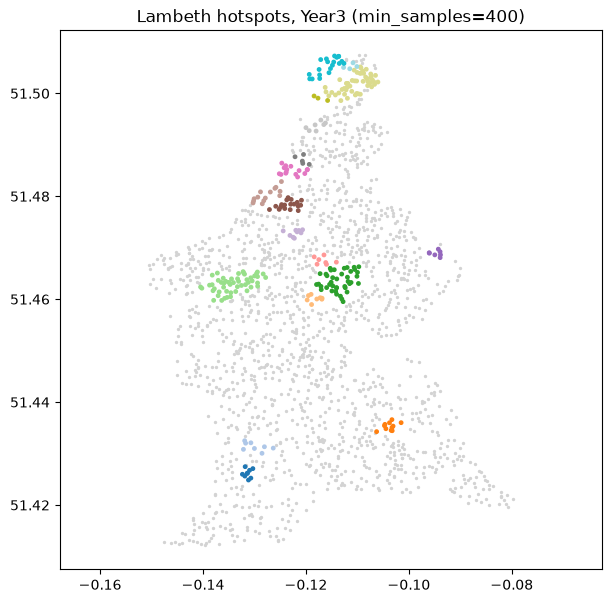

In [100]:
noise = points3[points3["cluster"] == -1]
hot = points3[points3["cluster"] != -1]

plt.figure(figsize=(7, 7))
plt.scatter(noise["Longitude"], noise["Latitude"], s=2, c="lightgrey")
plt.scatter(hot["Longitude"], hot["Latitude"], s=6, c=hot["cluster"], cmap="tab20")
plt.title(f"Lambeth hotspots, Year3 (min_samples={MIN_SAMPLES})")
plt.axis("equal")
plt.show()

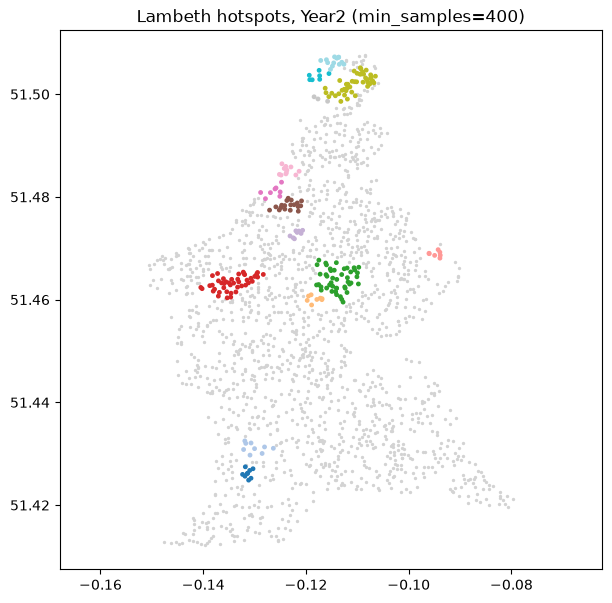

In [101]:
coords = np.radians(points2[["Latitude", "Longitude"]])

db = DBSCAN(eps=EPS_M / EARTH_RADIUS_M, min_samples=MIN_SAMPLES,
            metric="haversine", algorithm="ball_tree")
db.fit(coords, sample_weight=points2["crimes"])
points2["cluster"] = db.labels_

noise = points2[points2["cluster"] == -1]
hot = points2[points2["cluster"] != -1]

plt.figure(figsize=(7, 7))
plt.scatter(noise["Longitude"], noise["Latitude"], s=2, c="lightgrey")
plt.scatter(hot["Longitude"], hot["Latitude"], s=6, c=hot["cluster"], cmap="tab20")
plt.title(f"Lambeth hotspots, Year2 (min_samples={MIN_SAMPLES})")
plt.axis("equal")
plt.show()

In [102]:
EPS_M = 150
MIN_SHARE = 0.01
MATCH_M = 300

In [103]:
def get_points(borough, year):
    sample = crimes[(crimes["Borough"] == borough) & (crimes["YearGroup"] == year)]
    return sample.groupby(["Latitude", "Longitude"]).size().reset_index(name="crimes")


def find_hotspots(points, min_samples):
    coords = np.radians(points[["Latitude", "Longitude"]])
    db = DBSCAN(eps=EPS_M / EARTH_RADIUS_M, min_samples=min_samples,
                metric="haversine", algorithm="ball_tree")
    db.fit(coords, sample_weight=points["crimes"])

    points = points.assign(cluster=db.labels_)
    hot = points[points["cluster"] != -1]          # keep only hotspot points

    # Centre of each hotspot = average position, weighted by crimes
    hot = hot.assign(lat_w=hot["Latitude"] * hot["crimes"],
                     lon_w=hot["Longitude"] * hot["crimes"])
    summary = hot.groupby("cluster")[["crimes", "lat_w", "lon_w"]].sum().reset_index()
    summary["Latitude"] = summary["lat_w"] / summary["crimes"]
    summary["Longitude"] = summary["lon_w"] / summary["crimes"]
    return summary[["Latitude", "Longitude", "crimes"]]

In [104]:
YEARS = ["Year1", "Year2", "Year3"]
results = []

for borough in sorted(crimes["Borough"].unique()):
    yearly_average = (crimes["Borough"] == borough).sum() / 3
    min_samples = int(yearly_average * MIN_SHARE)

    for year in YEARS:
        hotspots = find_hotspots(get_points(borough, year), min_samples)
        hotspots["Borough"] = borough
        hotspots["YearGroup"] = year
        results.append(hotspots)

all_hotspots = pd.concat(results, ignore_index=True)
all_hotspots.groupby("YearGroup").size()

YearGroup
Year1    303
Year2    312
Year3    312
dtype: int64

In [105]:
all_hotspots[all_hotspots["Borough"] == "Lambeth"]

,Latitude,Longitude,crimes,Borough,YearGroup
599,51.425922,-0.131363,488,Lambeth,Year1
600,51.431417,-0.129981,555,Lambeth,Year1
601,51.460103,-0.118174,585,Lambeth,Year1
602,51.462881,-0.114286,4165,Lambeth,Year1
603,51.462949,-0.135687,2444,Lambeth,Year1
604,51.472374,-0.122472,835,Lambeth,Year1
605,51.477739,-0.123226,838,Lambeth,Year1
606,51.481014,-0.126652,587,Lambeth,Year1
607,51.485205,-0.123997,1064,Lambeth,Year1
608,51.499351,-0.118117,674,Lambeth,Year1


In [106]:
from sklearn.neighbors import BallTree

def nearest(from_df, to_df):
    """For each hotspot in from_df: distance in metres to the closest hotspot in to_df, and which one."""
    if len(from_df) == 0 or len(to_df) == 0:
        return np.full(len(from_df), np.inf), np.full(len(from_df), -1)
    tree = BallTree(np.radians(to_df[["Latitude", "Longitude"]]), metric="haversine")
    dist, idx = tree.query(np.radians(from_df[["Latitude", "Longitude"]]), k=1)
    return dist[:, 0] * EARTH_RADIUS_M, idx[:, 0]

In [107]:
labelled = []

for borough in all_hotspots["Borough"].unique():
    b = all_hotspots[all_hotspots["Borough"] == borough]

    first = b[b["YearGroup"] == "Year1"].copy()
    first["status"] = "baseline"
    first["prev_crimes"] = np.nan
    labelled.append(first)

    for prev_year, year in [("Year1", "Year2"), ("Year2", "Year3")]:
        prev = b[b["YearGroup"] == prev_year].reset_index(drop=True)
        cur = b[b["YearGroup"] == year].reset_index(drop=True)

        # This year's hotspots: established or new?
        dist, idx = nearest(cur, prev)
        matched = dist <= MATCH_M
        cur["status"] = np.where(matched, "established", "new")
        cur["prev_crimes"] = np.where(matched, prev["crimes"].reindex(idx).values, np.nan)

        # Last year's hotspots with nothing near them now: faded
        dist_back, _ = nearest(prev, cur)
        faded = prev[dist_back > MATCH_M].copy()
        faded["YearGroup"] = year
        faded["status"] = "faded"
        faded["prev_crimes"] = faded["crimes"]
        faded["crimes"] = np.nan          # it's not a hotspot this year

        labelled.extend([cur, faded])

hotspots = pd.concat(labelled, ignore_index=True)
hotspots["change_pct"] = ((hotspots["crimes"] - hotspots["prev_crimes"]) / hotspots["prev_crimes"] * 100).round(1)

hotspots.groupby(["YearGroup", "status"]).size()

YearGroup  status     
Year1      baseline       303
Year2      established    249
           faded           56
           new             63
Year3      established    249
           faded           65
           new             63
dtype: int64

In [108]:
hotspots[hotspots["Borough"] == "Lambeth"].sort_values(["YearGroup", "status"])

,Latitude,Longitude,crimes,Borough,YearGroup,status,prev_crimes,change_pct
676,51.425922,-0.131363,488.0,Lambeth,Year1,baseline,NaN,NaN
677,51.431417,-0.129981,555.0,Lambeth,Year1,baseline,NaN,NaN
678,51.460103,-0.118174,585.0,Lambeth,Year1,baseline,NaN,NaN
679,51.462881,-0.114286,4165.0,Lambeth,Year1,baseline,NaN,NaN
680,51.462949,-0.135687,2444.0,Lambeth,Year1,baseline,NaN,NaN
681,51.472374,-0.122472,835.0,Lambeth,Year1,baseline,NaN,NaN
682,51.477739,-0.123226,838.0,Lambeth,Year1,baseline,NaN,NaN
683,51.481014,-0.126652,587.0,Lambeth,Year1,baseline,NaN,NaN
684,51.485205,-0.123997,1064.0,Lambeth,Year1,baseline,NaN,NaN
685,51.499351,-0.118117,674.0,Lambeth,Year1,baseline,NaN,NaN


In [109]:
hotspots.groupby(["YearGroup", "status"]).size()

YearGroup  status     
Year1      baseline       303
Year2      established    249
           faded           56
           new             63
Year3      established    249
           faded           65
           new             63
dtype: int64

In [110]:
import json
import os

OUT = "../web/data"
os.makedirs(OUT, exist_ok=True)

def clean(value):
    return None if pd.isna(value) else round(float(value), 1)

for year in YEARS:
    rows = hotspots[hotspots["YearGroup"] == year]
    features = []
    for _, r in rows.iterrows():
        features.append({
            "type": "Feature",
            "geometry": {"type": "Point",
                         "coordinates": [round(r["Longitude"], 5), round(r["Latitude"], 5)]},
            "properties": {
                "borough": r["Borough"],
                "status": r["status"],
                "crimes": clean(r["crimes"]),
                "prev_crimes": clean(r["prev_crimes"]),
                "change_pct": clean(r["change_pct"]),
            },
        })
    with open(f"{OUT}/hotspots_{year}.geojson", "w") as f:
        json.dump({"type": "FeatureCollection", "features": features}, f)
    print(year, len(features), "hotspots saved")

Year1 303 hotspots saved
Year2 368 hotspots saved
Year3 377 hotspots saved
